In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

# Notebook is in .../Group Sprint 1/notebooks
BASE = Path("..").resolve()
CLEAN_PATH = BASE / "data" / "cleaned" / "shots_cleaned.csv"
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_csv(CLEAN_PATH)
print(df.shape)

# Placeholder split: agreed with the group, since all four models must use the same rows
TRAIN_SEASONS = ["2021/22", "2022/23", "2023/24"]
VAL_SEASONS   = ["2024/25"]
TEST_SEASONS  = ["2025/26"]   # held out: do not use until decisions are frozen
# 2026/27 is excluded (only 60 matches so far)

train = df[df["season"].isin(TRAIN_SEASONS)].copy()
val   = df[df["season"].isin(VAL_SEASONS)].copy()
print(f"train: {len(train)}  validation: {len(val)}")

y_train = train["result"].to_numpy()
y_val   = val["result"].to_numpy()

(50798, 38)
train: 29813  validation: 9844


In [3]:
class NullModel:
    """Predicts the training goal rate for every shot."""
    def fit(self, y):
        self.p_ = float(np.mean(y))
        return self

    def predict_proba(self, n):
        return np.full(n, self.p_)

null_model = NullModel().fit(y_train)
print(f"Null model prediction (training goal rate): {null_model.p_:.4f}")
print(f"Validation goal rate:                        {y_val.mean():.4f}")

p_null_train = null_model.predict_proba(len(y_train))
p_null_val   = null_model.predict_proba(len(y_val))

Null model prediction (training goal rate): 0.1097
Validation goal rate:                        0.1098


In [4]:
def evaluate(y_true, p_pred):
    p = np.clip(p_pred, 1e-15, 1 - 1e-15)
    return {
        "log_loss": log_loss(y_true, p),
        "brier": brier_score_loss(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": p.mean(),
        "observed_rate": y_true.mean(),
    }

results = pd.DataFrame({
    ("train", "null"): evaluate(y_train, p_null_train),
    ("train", "understat_xg"): evaluate(y_train, train["xg"].to_numpy()),
    ("validation", "null"): evaluate(y_val, p_null_val),
    ("validation", "understat_xg"): evaluate(y_val, val["xg"].to_numpy()),
}).T.round(4)
results.index.names = ["split", "model"]
display(results)

# Sanity check: null log loss equals the binary entropy of the goal rate
p = null_model.p_
entropy = -(p * np.log(p) + (1 - p) * np.log(1 - p))
print(f"Binary entropy of training goal rate: {entropy:.4f}")

log_loss   brier  roc_auc  mean_pred  observed_rate
split      model                                                            
train      null            0.3459  0.0977   0.5000     0.1097         0.1097
           understat_xg    0.2658  0.0752   0.8116     0.1191         0.1097
validation null            0.3461  0.0978   0.5000     0.1097         0.1098
           understat_xg    0.2715  0.0774   0.8058     0.1256         0.1098

Binary entropy of training goal rate: 0.3459


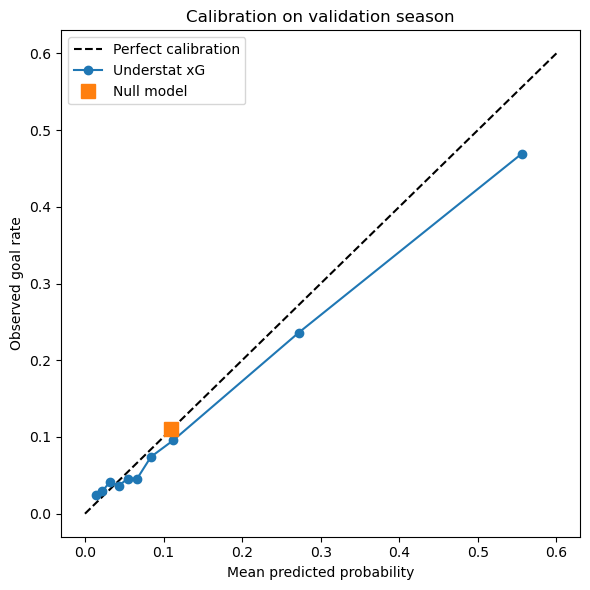

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.6], [0, 0.6], "k--", label="Perfect calibration")

frac_pos, mean_pred = calibration_curve(y_val, val["xg"], n_bins=10, strategy="quantile")
ax.plot(mean_pred, frac_pos, "o-", label="Understat xG")
ax.plot(p_null_val[0], y_val.mean(), "s", markersize=10, label="Null model")

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed goal rate")
ax.set_title("Calibration on validation season")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_null_model_calibration.png", dpi=200)
plt.show()

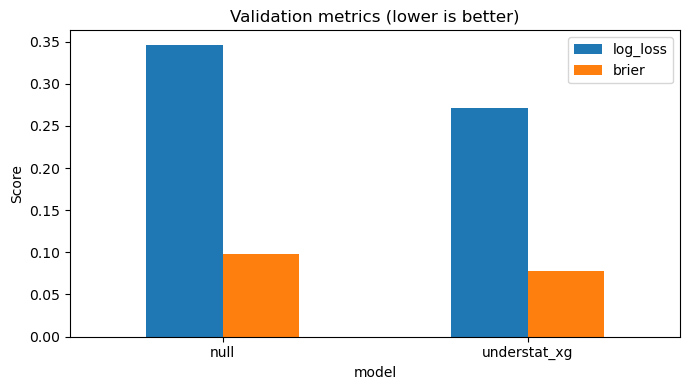

In [6]:
plot_df = results.xs("validation", level="split")[["log_loss", "brier"]]
ax = plot_df.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Validation metrics (lower is better)")
ax.set_ylabel("Score")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_null_model_metrics.png", dpi=200)
plt.show()